# Classificação e Dados Agrupados na Prática *(Nível Básico)*

Quando você tem **várias medições do mesmo paciente, árvore ou parcela** (`paciente_id`), uma divisão aleatória comum vaza informação entre treino e validação.

Aqui mostramos como resolver isso em 10 linhas passando `group_col='paciente_id'` no `run_experiment(...)`.

In [1]:
# Instalação automática apenas quando executado no Google Colab
import subprocess, sys
if "google.colab" in sys.modules:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "git+https://github.com/aleerangel/experimental-ml-framework.git",
    ])

In [2]:
# Helper de exibição rica (funciona em Jupyter/Colab e em Python puro)
def exibir_markdown(texto: str) -> None:
    try:
        from IPython.display import Markdown, display
        display(Markdown(texto))
    except ImportError:
        print(texto)

def exibir_svg(svg_bytes: bytes | str) -> None:
    svg_str = svg_bytes.decode("utf-8") if isinstance(svg_bytes, bytes) else svg_bytes
    try:
        from IPython.display import SVG, display
        display(SVG(svg_str))
    except ImportError:
        print(f"[Figura SVG gerada: {len(svg_str)} caracteres]")

## 1. Base Clínica Sintética e Classificador com Probabilidades

In [3]:
from pathlib import Path
import tempfile
import numpy as np

from experimental_ml import run_experiment
from experimental_ml.models import DummyBaselineModel

class ClassificadorLinear:
    def fit(self, X: np.ndarray, y: np.ndarray) -> "ClassificadorLinear":
        X_aug = np.column_stack([X, np.ones(len(X))])
        coef, *_ = np.linalg.lstsq(X_aug, y.astype(float), rcond=None)
        self.w_ = coef[:-1]
        self.b_ = float(coef[-1])
        return self

    def predict_proba(self, X: np.ndarray) -> np.ndarray:
        z = np.clip(X @ self.w_ + self.b_, -20.0, 20.0)
        p1 = 1.0 / (1.0 + np.exp(-z))
        return np.column_stack([1.0 - p1, p1])

    def predict(self, X: np.ndarray) -> np.ndarray:
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

rng = np.random.default_rng(7)
pacientes = [f"P{g}" for g in range(1, 13) for _ in range(3)]
diagnostico = [0 if g <= 6 else 1 for g in range(1, 13) for _ in range(3)]
bio_a = rng.normal(loc=np.array(diagnostico) * 1.3, scale=0.7).tolist()
bio_b = rng.normal(loc=0.5, scale=1.0, size=36).tolist()

dados_clinicos = {
    "paciente_id": pacientes,
    "biomarcador_a": bio_a,
    "biomarcador_b": bio_b,
    "diagnostico": diagnostico,
}

work_dir = Path(tempfile.mkdtemp(prefix="expml_basico_02_"))
resultado = run_experiment(
    data=dados_clinicos,
    target="diagnostico",
    task="binary_classification",
    group_col="paciente_id",        # garante que o mesmo paciente nunca apareça no treino e validação
    models={
        "Baseline Majoritário": DummyBaselineModel(strategy="most_frequent"),
        "Classificador Linear": ClassificadorLinear(),
    },
    output_dir=work_dir / "exp_clinico",
    cv_folds=4,
    metrics=["accuracy", "f1", "roc_auc"],
)
print(resultado.summary())

=== Resumo do Experimento ===
Diretório: /tmp/expml_basico_02_l_xvisdk/exp_clinico
Células concluídas: 8 (falhas: 0)
Líder observado (accuracy): ('classificador_linear', 'todas_features')
Status estatístico: 0 of 1 comparison(s) reached adjusted significance (p_adj < 0.050); 1 comparison(s) had insufficient statistical evidence to reject H0 (non-significance does not imply equivalence).

Desempenho por configuração:
  - ('baseline_majorit_rio', 'todas_features'): [VALID] accuracy=0.3333±0.0000, f1=0.2500±0.2887, roc_auc=0.5000±0.0000
  - ('classificador_linear', 'todas_features'): [VALID] accuracy=0.5556±0.1571, f1=0.6750±0.1500, roc_auc=0.8472±0.1052

Conclusão: On primary metric 'accuracy' (MAXIMIZE), observed leader is classificador_linear/todas_features with mean=0.5556. 0 of 1 comparison(s) reached adjusted significance (p_adj < 0.050); 1 comparison(s) had insufficient statistical evidence to reject H0 (non-significance does not imply equivalence). Comparison baseline_majorit_rio/

## 2. Exibindo a Tabela Comparativa e o Gráfico SVG

### Desempenho por Modelo (Isolado por Paciente)

### Predictive Performance

| Model | Scenario | Metric | Status | Mean | SD | Median | IQR | Coverage |
| :--- | :--- | :--- | :---: | ---: | ---: | ---: | ---: | ---: |
| baseline_majorit_rio | todas_features | accuracy | VALID | 0.3333 | 0.0000 | 0.3333 | 0.0000 | 100.00% |
| baseline_majorit_rio | todas_features | f1 | VALID | 0.2500 | 0.2887 | 0.2500 | 0.5000 | 100.00% |
| baseline_majorit_rio | todas_features | roc_auc | VALID | 0.5000 | 0.0000 | 0.5000 | 0.0000 | 100.00% |
| classificador_linear | todas_features | accuracy | VALID | 0.5556 | 0.1571 | 0.6111 | 0.1667 | 100.00% |
| classificador_linear | todas_features | f1 | VALID | 0.6750 | 0.1500 | 0.7000 | 0.2250 | 100.00% |
| classificador_linear | todas_features | roc_auc | VALID | 0.8472 | 0.1052 | 0.8056 | 0.0972 | 100.00% |


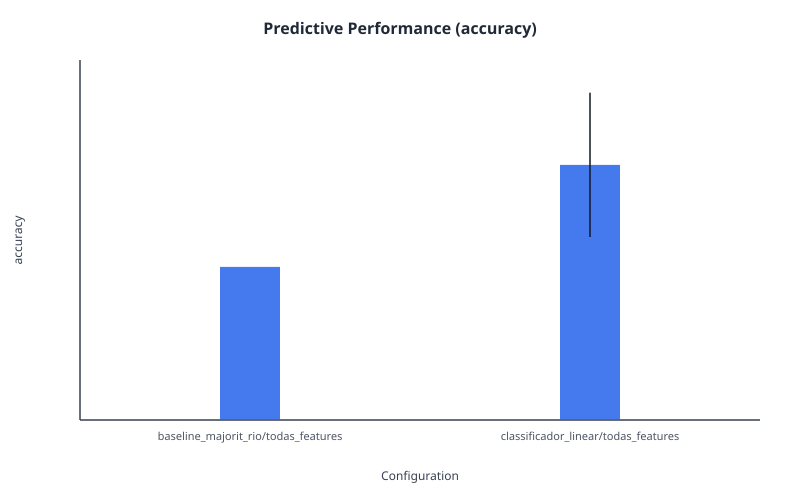

In [4]:
from experimental_ml.reporting import (
    ReportAudience,
    ReportContentSelection,
    ReportFamily,
    build_figure_spec,
    build_table_model,
    load_experiment_artifacts_readonly,
    render_figure,
    render_table_markdown,
    select_report_content,
)

loaded = load_experiment_artifacts_readonly(resultado.experiment_dir)
sel = select_report_content(loaded, ReportContentSelection(audience=ReportAudience.FULL_LAB))

tabela = build_table_model(ReportFamily.D_PREDICTIVE_PERFORMANCE, loaded, sel)
exibir_markdown("### Desempenho por Modelo (Isolado por Paciente)\n\n" + render_table_markdown(tabela))

fig = build_figure_spec(ReportFamily.D_PREDICTIVE_PERFORMANCE, loaded, sel)
exibir_svg(render_figure(fig, fmt="svg"))